# ML CIE-2 – Activity 2

## Indian House Price Prediction Using Simple Linear Regression

### 1. Introduction
Machine Learning helps computers learn patterns from data and make predictions. In this activity, we will develop a Simple Linear Regression model to predict Indian house prices based on carpet area.

### 2. Objectives
- Explore a real-world Indian housing dataset.
- Perform basic data inspection and cleaning.
- Identify input and target variables.
- Train a Linear Regression model.
- Evaluate the model using regression metrics.
- Visualise actual and predicted house prices.
- Predict the price of a new house.

### 3. Dataset Description
**Dataset Name:** House Price (India)  
**Dataset Author:** Juhi Bhojani  
**Source:** [Kaggle – House Price (India)](https://www.kaggle.com/datasets/juhibhojani/house-price)

The dataset contains Indian residential property listings with information such as location, carpet area, bathrooms and property prices.

### 4. Tools and Libraries
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [14]:
import os

files = os.listdir('/content')

print("Files available in Colab:")
for file in files:
    print(file)

Files available in Colab:
.config
house_data
house_prices.csv.zip
sample_data


In [15]:
import zipfile
import os

zip_path = '/content/house_prices.csv.zip'
extract_path = '/content/activity2_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print("Files inside ZIP:", zip_ref.namelist())
    zip_ref.extractall(extract_path)

print("\nDataset extracted successfully!")

Files inside ZIP: ['house_prices.csv']

Dataset extracted successfully!


In [16]:
import os

for root, folders, files in os.walk('/content/activity2_data'):
    for file in files:
        print("Extracted file:", file)

Extracted file: house_prices.csv


In [17]:
import pandas as pd
import os

csv_path = '/content/activity2_data/house_prices.csv'

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (187531, 21)


In [18]:
df.head()


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [19]:
print("Total number of columns:", len(df.columns))

print("\nColumn names:")
for column in df.columns:
    print(column)

Total number of columns: 21

Column names:
Index
Title
Description
Amount(in rupees)
Price (in rupees)
location
Carpet Area
Status
Floor
Transaction
Furnishing
facing
overlooking
Society
Bathroom
Balcony
Car Parking
Ownership
Super Area
Dimensions
Plot Area


In [20]:
print("Data types of each column:")
print(df.dtypes)

Data types of each column:
Index                  int64
Title                 object
Description           object
Amount(in rupees)     object
Price (in rupees)    float64
location              object
Carpet Area           object
Status                object
Floor                 object
Transaction           object
Furnishing            object
facing                object
overlooking           object
Society               object
Bathroom              object
Balcony               object
Car Parking           object
Ownership             object
Super Area            object
Dimensions           float64
Plot Area            float64
dtype: object


In [21]:
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,187531.000000,1.698660e+05,0.0,0.0
mean,93765.000000,7.583772e+03,NaN,NaN
std,54135.681003,2.724171e+04,NaN,NaN
min,0.000000,0.000000e+00,NaN,NaN
25%,46882.500000,4.297000e+03,NaN,NaN
50%,93765.000000,6.034000e+03,NaN,NaN
75%,140647.500000,9.450000e+03,NaN,NaN
max,187530.000000,6.700000e+06,NaN,NaN


In [22]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64


In [23]:
print("Total duplicate records:", df.duplicated().sum())


Total duplicate records: 0


In [24]:
print("Carpet Area values:")
print(df['Carpet Area'].head(10))

print("\nHouse Price values:")
print(df['Amount(in rupees)'].head(10))

Carpet Area values:
0    500 sqft
1    473 sqft
2    779 sqft
3    530 sqft
4    635 sqft
5         NaN
6    550 sqft
7         NaN
8         NaN
9    900 sqft
Name: Carpet Area, dtype: object

House Price values:
0      42 Lac 
1      98 Lac 
2     1.40 Cr 
3      25 Lac 
4     1.60 Cr 
5      45 Lac 
6    16.5 Lac 
7      60 Lac 
8      60 Lac 
9     1.60 Cr 
Name: Amount(in rupees), dtype: object


In [25]:
import re

# Extract numerical area values in square feet
area_values = df['Carpet Area'].astype(str).str.extract(
    r'([\d,.]+)\s*sq\.?\s*ft|([\d,.]+)\s*sqft',
    flags=re.IGNORECASE
)

area_values = area_values.bfill(axis=1).iloc[:, 0]

df['Area_sqft'] = pd.to_numeric(
    area_values.str.replace(',', '', regex=False),
    errors='coerce'
)

print("Original carpet area:")
print(df['Carpet Area'].head())

print("\nConverted carpet area:")
print(df['Area_sqft'].head())

Original carpet area:
0    500 sqft
1    473 sqft
2    779 sqft
3    530 sqft
4    635 sqft
Name: Carpet Area, dtype: object

Converted carpet area:
0    500.0
1    473.0
2    779.0
3    530.0
4    635.0
Name: Area_sqft, dtype: float64


/tmp/ipykernel_739/2455920112.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  area_values = area_values.bfill(axis=1).iloc[:, 0]


In [26]:
print("Total valid carpet areas:", df['Area_sqft'].notna().sum())

print("\nMissing carpet areas after conversion:",
      df['Area_sqft'].isnull().sum())

print("\nConverted area statistics:")
print(df['Area_sqft'].describe())

Total valid carpet areas: 100428

Missing carpet areas after conversion: 87103

Converted area statistics:
count    100428.000000
mean       1268.525909
std        3129.311735
min           1.000000
25%         801.000000
50%        1071.000000
75%        1500.000000
max      709222.000000
Name: Area_sqft, dtype: float64


In [27]:
def convert_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value).lower().replace(',', '').strip()

    if 'call' in value:
        return np.nan

    match = re.search(r'(\d+(?:\.\d+)?)\s*(crore|cr|lakh|lac)', value)

    if match:
        number = float(match.group(1))
        unit = match.group(2)

        if unit in ['crore', 'cr']:
            return number * 10000000
        elif unit in ['lakh', 'lac']:
            return number * 100000

    return np.nan


df['Price_Rupees'] = df['Amount(in rupees)'].apply(convert_price)

print("Original house prices:")
print(df['Amount(in rupees)'].head(10))

print("\nConverted house prices:")
print(df['Price_Rupees'].head(10))

Original house prices:
0      42 Lac 
1      98 Lac 
2     1.40 Cr 
3      25 Lac 
4     1.60 Cr 
5      45 Lac 
6    16.5 Lac 
7      60 Lac 
8      60 Lac 
9     1.60 Cr 
Name: Amount(in rupees), dtype: object

Converted house prices:
0     4200000.0
1     9800000.0
2    14000000.0
3     2500000.0
4    16000000.0
5     4500000.0
6     1650000.0
7     6000000.0
8     6000000.0
9    16000000.0
Name: Price_Rupees, dtype: float64


In [28]:
# Select the required columns
model_df = df[['Area_sqft', 'Price_Rupees']].copy()

# Remove missing values
model_df = model_df.dropna()

# Remove zero and negative values
model_df = model_df[
    (model_df['Area_sqft'] > 0) &
    (model_df['Price_Rupees'] > 0)
]

# Reset row numbering
model_df = model_df.reset_index(drop=True)

print("Clean dataset created successfully!")
print("Original dataset rows:", len(df))
print("Clean dataset rows:", len(model_df))
print("Removed rows:", len(df) - len(model_df))

print("\nFirst five clean records:")
print(model_df.head())

Clean dataset created successfully!
Original dataset rows: 187531
Clean dataset rows: 95986
Removed rows: 91545

First five clean records:
   Area_sqft  Price_Rupees
0      500.0     4200000.0
1      473.0     9800000.0
2      779.0    14000000.0
3      530.0     2500000.0
4      635.0    16000000.0


In [29]:
print("Final dataset shape:", model_df.shape)

print("\nData types:")
print(model_df.dtypes)

print("\nSummary statistics:")
print(model_df.describe())

print("\nMissing values:")
print(model_df.isnull().sum())

Final dataset shape: (95986, 2)

Data types:
Area_sqft       float64
Price_Rupees    float64
dtype: object

Summary statistics:
           Area_sqft  Price_Rupees
count   95986.000000  9.598600e+04
mean     1288.851853  1.363884e+07
std      3196.537026  5.246864e+07
min         1.000000  1.100000e+05
25%       850.000000  4.852500e+06
50%      1100.000000  8.200000e+06
75%      1537.000000  1.750000e+07
max    709222.000000  1.400300e+10

Missing values:
Area_sqft       0
Price_Rupees    0
dtype: int64


In [30]:
# Select input feature (X)
X = model_df[['Area_sqft']]

# Select target variable (y)
y = model_df['Price_Rupees']

print("Input feature (X):")
print(X.head())

print("\nTarget variable (y):")
print(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Input feature (X):
   Area_sqft
0      500.0
1      473.0
2      779.0
3      530.0
4      635.0

Target variable (y):
0     4200000.0
1     9800000.0
2    14000000.0
3     2500000.0
4    16000000.0
Name: Price_Rupees, dtype: float64

Shape of X: (95986, 1)
Shape of y: (95986,)


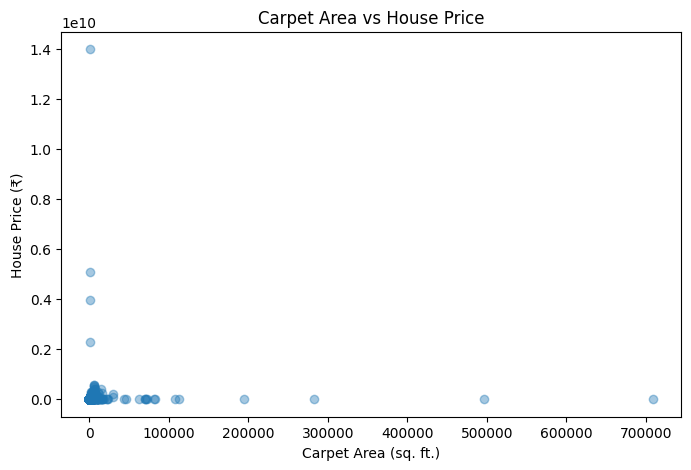

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['Area_sqft'],
    y,
    alpha=0.4
)

plt.title('Carpet Area vs House Price')
plt.xlabel('Carpet Area (sq. ft.)')
plt.ylabel('House Price (₹)')

plt.show()

In [32]:
print("Area statistics:")
print(model_df['Area_sqft'].describe(
    percentiles=[0.90, 0.95, 0.99]
))

print("\nPrice statistics:")
print(model_df['Price_Rupees'].describe(
    percentiles=[0.90, 0.95, 0.99]
))

print("\n10 largest carpet area records:")
print(model_df.nlargest(10, 'Area_sqft'))

print("\n10 highest price records:")
print(model_df.nlargest(10, 'Price_Rupees'))

Area statistics:
count     95986.000000
mean       1288.851853
std        3196.537026
min           1.000000
50%        1100.000000
90%        2000.000000
95%        2550.000000
99%        4583.000000
max      709222.000000
Name: Area_sqft, dtype: float64

Price statistics:
count    9.598600e+04
mean     1.363884e+07
std      5.246864e+07
min      1.100000e+05
50%      8.200000e+06
90%      2.850000e+07
95%      3.980000e+07
99%      7.000000e+07
max      1.400300e+10
Name: Price_Rupees, dtype: float64

10 largest carpet area records:
       Area_sqft  Price_Rupees
84439   709222.0     6000000.0
75595   495970.0     1900000.0
74810   282004.0     2000000.0
18742   194936.0    26000000.0
74895   113134.0     5600000.0
37074   107806.0     6800000.0
91593    81845.0     4500000.0
90155    81675.0     4570000.0
90156    71775.0     4020000.0
90172    71025.0     3980000.0

10 highest price records:
       Area_sqft  Price_Rupees
92143     1252.0  1.400300e+10
90083      970.0  5.100400e+0

In [33]:
# Calculate 99th percentile limits
area_limit = model_df['Area_sqft'].quantile(0.99)
price_limit = model_df['Price_Rupees'].quantile(0.99)

# Filter extreme observations
filtered_df = model_df[
    (model_df['Area_sqft'] <= area_limit) &
    (model_df['Price_Rupees'] <= price_limit)
].copy()

filtered_df = filtered_df.reset_index(drop=True)

print("Dataset before filtering:", len(model_df))
print("Dataset after filtering:", len(filtered_df))
print("Records removed:", len(model_df) - len(filtered_df))

print("\nFiltered dataset summary:")
print(filtered_df.describe())

Dataset before filtering: 95986
Dataset after filtering: 94616
Records removed: 1370

Filtered dataset summary:
          Area_sqft  Price_Rupees
count  94616.000000  9.461600e+04
mean    1216.049241  1.239914e+07
std      601.654994  1.124189e+07
min        1.000000  1.100000e+05
25%      836.000000  4.800000e+06
50%     1080.000000  8.000000e+06
75%     1500.000000  1.750000e+07
max     4555.000000  7.000000e+07


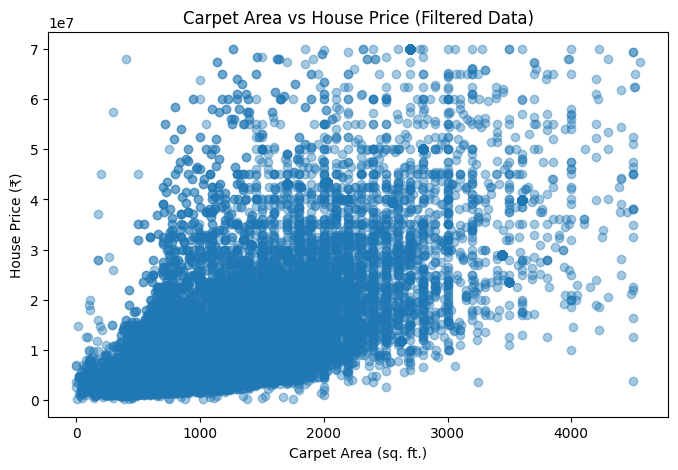

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(
    filtered_df['Area_sqft'],
    filtered_df['Price_Rupees'],
    alpha=0.4
)

plt.title('Carpet Area vs House Price (Filtered Data)')
plt.xlabel('Carpet Area (sq. ft.)')
plt.ylabel('House Price (₹)')

plt.show()

In [35]:
# Select input feature
X = filtered_df[['Area_sqft']]

# Select target variable
y = filtered_df['Price_Rupees']

print("Input feature shape:", X.shape)
print("Target variable shape:", y.shape)

Input feature shape: (94616, 1)
Target variable shape: (94616,)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 75692
Testing records: 18924


In [38]:
print("Model Coefficient:", model.coef_[0])
print("Model Intercept:", model.intercept_)

Model Coefficient: 13988.389639138777
Model Intercept: -4635544.875700079


In [39]:
# Predict house prices using test data
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predicted prices:
[19144717.51083584 12849942.17322339 10304055.25890014 10192148.14178702
 24740073.36649135  2288707.99567362 23341234.40257747  4876560.07891429
 20403672.57835833 19158705.90047498]


In [40]:
comparison = pd.DataFrame({
    'Actual Price (₹)': y_test.values,
    'Predicted Price (₹)': y_pred
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price (₹),Predicted Price (₹)
0,28500000.0,1.914472e+07
1,8500000.0,1.284994e+07
2,6900000.0,1.030406e+07
3,6000000.0,1.019215e+07
4,26800000.0,2.474007e+07
5,2300000.0,2.288708e+06
6,8000000.0,2.334123e+07
7,3100000.0,4.876560e+06
8,22500000.0,2.040367e+07
9,43000000.0,1.915871e+07


In [41]:
# Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 4912634.243971397
MSE: 57731081132080.96
RMSE: 7598097.204700724
R2 Score: 0.5631904821830939


### Interpretation of Model Evaluation

The Linear Regression model achieved an R² score of approximately 0.5632, indicating that it explains around 56.32% of the variation in house prices in the test dataset.

The Mean Absolute Error (MAE) is approximately ₹49.13 lakh, while the Root Mean Squared Error (RMSE) is approximately ₹75.99 lakh.

These results indicate that the model identifies a relationship between carpet area and house price, but its predictions still have considerable errors. This may be because property prices also depend on location, amenities, property condition and other factors.

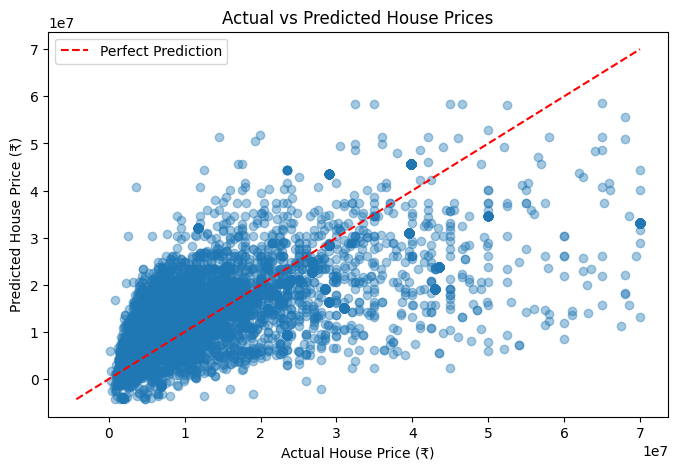

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual House Price (₹)')
plt.ylabel('Predicted House Price (₹)')
plt.legend()

plt.show()

### Interpretation of Actual vs Predicted Graph

The graph compares actual house prices with the prices predicted by the Linear Regression model. The red dashed line represents perfect prediction, where actual and predicted prices are equal.

Some points are close to the reference line, while many points are scattered away from it. This indicates that the model makes reasonably close predictions for some properties but produces larger errors for others. The model also tends to underestimate some high-priced properties.

Overall, the graph indicates moderate predictive performance and shows that additional features may improve accuracy.

In [43]:
# New house carpet area
new_house = pd.DataFrame({
    'Area_sqft': [1200]
})

# Predict house price
predicted_price = model.predict(new_house)

print("New House Details")
print("------------------")
print("Carpet Area: 1200 sq. ft.")
print("Predicted House Price: ₹", round(predicted_price[0], 2))

New House Details
------------------
Carpet Area: 1200 sq. ft.
Predicted House Price: ₹ 12150522.69


## 13. Conclusion

In this activity, I developed a Simple Linear Regression model to predict Indian house prices using carpet area as the input feature.

The House Price (India) dataset was collected from Kaggle. Data inspection and cleaning were performed to convert carpet area and house prices into numerical values. Extreme observations were filtered using the 99th percentile as an upper limit.

The final filtered dataset contained 94,616 records. The data was divided into 80% training data and 20% testing data.

The Linear Regression model achieved the following results:

- MAE: ₹49,12,634.24
- MSE: 57,731,081,132,080.96
- RMSE: ₹75,98,097.20
- R² Score: 0.5632

The model explained approximately 56.32% of the variation in house prices on the test dataset.

A new house with a carpet area of 1,200 sq. ft. was used to demonstrate price prediction.

The activity helped me understand data inspection, data cleaning, feature selection, train-test splitting, Linear Regression, prediction and model evaluation.

### Limitations

The model uses only carpet area to predict house prices. Actual property prices also depend on location, property condition, amenities, construction quality and other factors. Therefore, using additional relevant features may improve prediction accuracy.